In [51]:
# ============================================================
# BAGIAN 0: SETUP AWAL
# ============================================================

# 1. SEED (WAJIB di paling atas - 3 digit terakhir NIM)
SEED = 389

# 2. Install library yang diperlukan
!pip install openpyxl -q

# 3. Import semua library yang akan dipakai di seluruh notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 4. Setup visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print(f"Setup berhasil. SEED yang digunakan: {SEED}")

Setup berhasil. SEED yang digunakan: 389


## 1. Pemahaman Masalah dan Data

**Tujuan Analisis:**
Mengelompokkan (segmentasi) kabupaten/kota di Indonesia berdasarkan indikator pembangunan manusia untuk mengidentifikasi kesenjangan antar daerah dan menemukan pola karakteristik wilayah.

**Pengguna Hasil:**
Pemerintah daerah (Bappeda), pembuat kebijakan publik, dan peneliti sosial-ekonomi.

**Keputusan yang Terbantu:**
Menentukan prioritas alokasi dana atau program intervensi spesifik. Misalnya, daerah di cluster "Tertinggal" mungkin butuh intervensi infrastruktur pendidikan (RLS/HLS), sedangkan daerah dengan pengeluaran tinggi tapi AHH rendah butuh fokus pada fasilitas kesehatan.

**Sumber Data:**
Kaggle (Sumber asli: Badan Pusat Statistik / Satu Data Indonesia).
Link: https://www.kaggle.com/datasets/sherlydwipuspita/ipm-indonesia-2023
Tanggal akses: 24 November 2026.

**Kesesuaian dengan Jalur C (Clustering):**

Dataset ini **tidak memiliki label/target kategori** yang harus diprediksi,
sehingga tidak cocok untuk Jalur A (Klasifikasi). Dataset ini juga tidak
memiliki target berupa angka kontinu yang harus diestimasi, sehingga tidak
cocok untuk Jalur B (Regresi).

Dataset ini **cocok untuk Jalur C (Clustering)** karena:
- **Tidak memiliki label**: Tujuannya adalah menemukan kelompok alami
  kabupaten/kota berdasarkan pola indikator pembangunan.
- **Memiliki ≥3 fitur numerik**: Dataset ini memiliki 5 fitur numerik
  (Jumlah AHH, Jumlah RLS, Jumlah HLS, Pengeluaran, Jumlah IPM),
  melebihi syarat minimal 3 fitur numerik.
- **Memiliki >200 baris**: Dataset berisi 514 kabupaten/kota,
  melebihi syarat minimal 200 baris.
- **Algoritma yang digunakan**: K-Means dengan pemilihan k menggunakan
  Elbow dan Silhouette, serta perbandingan tanpa vs dengan scaling.

**Deskripsi Kolom:**
| Nama Kolom | Tipe Data | Arti | Satuan |
|---|---|---|---|
| Kota | Object | Nama Kabupaten/Kota | - |
| Jumlah AHH | Float | Angka Harapan Hidup | Tahun |
| Jumlah RLS | Float | Rata-rata Lama Sekolah | Tahun |
| Jumlah HLS | Float | Harapan Lama Sekolah | Tahun |
| Pengeluaran | Float | Pengeluaran per Kapita yang Disesuaikan | Ribu Rupiah |
| Jumlah IPM | Float | Indeks Pembangunan Manusia | Indeks (0-100) |

In [52]:
# ============================================================
# 1.1 MEMUAT DATASET (DATA MENTAH)
# ============================================================
df = pd.read_excel('IPM-Indonesia-2023.xlsx', engine='openpyxl')

print("="*70)
print("UKURAN DATASET MENTAH")
print("="*70)
print(f"Jumlah Baris: {df.shape[0]}")
print(f"Jumlah Kolom: {df.shape[1]}")

print("\n" + "="*70)
print("NAMA KOLOM MENTAH")
print("="*70)
print(df.columns.tolist())

print("\n" + "="*70)
print("5 BARIS PERTAMA (DATA MENTAH)")
print("="*70)
display(df.head())

print("\n" + "="*70)
print("TIPE DATA PER KOLOM")
print("="*70)
print(df.dtypes)

print("\n" + "="*70)
print("CEK MISSING VALUE")
print("="*70)
print(df.isnull().sum())

UKURAN DATASET MENTAH
Jumlah Baris: 514
Jumlah Kolom: 12

NAMA KOLOM MENTAH
['Provinsi', 'Kota', 'Jumlah AHH', 'AHH', 'Jumlah RLS', 'RLS', 'Jumlah HLS', 'HLS', 'Pengeluaran', 'PPK', 'Jumlah IPM', 'IPM']

5 BARIS PERTAMA (DATA MENTAH)


,Provinsi,Kota,Jumlah AHH,AHH,Jumlah RLS,RLS,Jumlah HLS,HLS,Pengeluaran,PPK,Jumlah IPM,IPM
0,Aceh,Simeuleu,69.57,Sedang,9.81,Sedang,14.28,Tinggi,7686,Rendah,68.06,Sedang
1,Aceh,Aceh Singkil,69.85,Sedang,8.70,Sedang,14.35,Tinggi,9374,Sedang,70.14,Tinggi
2,Aceh,Aceh Selatan,70.33,Tinggi,8.91,Sedang,14.70,Tinggi,8712,Sedang,68.44,Sedang
3,Aceh,Aceh Tenggara,72.62,Tinggi,10.09,Tinggi,14.27,Tinggi,8566,Sedang,71.05,Tinggi
4,Aceh,Aceh Timur,72.13,Tinggi,8.47,Sedang,13.07,Tinggi,9436,Sedang,69.32,Sedang



TIPE DATA PER KOLOM
Provinsi        object
Kota            object
Jumlah AHH     float64
AHH             object
Jumlah RLS     float64
RLS             object
Jumlah HLS     float64
HLS             object
Pengeluaran      int64
PPK             object
Jumlah IPM     float64
IPM             object
dtype: object

CEK MISSING VALUE
Provinsi       0
Kota           0
Jumlah AHH     0
AHH            0
Jumlah RLS     0
RLS            0
Jumlah HLS     0
HLS            0
Pengeluaran    0
PPK            0
Jumlah IPM     0
IPM            0
dtype: int64


### Keputusan saya

Saya memilih dataset IPM-Indonesia-2023 karena:

1. **Sesuai Jalur C (Clustering)**: Dataset tidak memiliki label target,
   melainkan hanya indikator pembangunan daerah yang cocok untuk
   segmentasi menggunakan K-Means.

2. **Memenuhi syarat minimal**: Dataset memiliki 514 baris (jauh melebihi
   minimal 200 baris) dan 5 fitur numerik (Jumlah AHH, Jumlah RLS,
   Jumlah HLS, Pengeluaran, Jumlah IPM) yang memenuhi syarat minimal
   4 fitur.

3. **Identifikasi awal struktur data**: Saya menemukan dataset ini
   memiliki pola unik — setiap indikator memiliki 2 kolom:
   kolom numerik (misal: `Jumlah AHH`) dan kolom kategori
   (misal: `AHH` berisi 'Rendah'/'Sedang'/'Tinggi'). Kolom kategori
   merupakan hasil binning dari kolom numeriknya, sehingga akan
   saya tangani di **Bagian 3: Pra-pemrosesan** untuk menghindari
   redundansi fitur dan kebocoran data.

4. **Relevansi bisnis**: Data ini digunakan oleh Bappeda dan pembuat
   kebijakan untuk menentukan prioritas pembangunan daerah, sehingga
   hasil clustering akan memiliki implikasi nyata.

## 2. Eksplorasi dan Visualisasi Data

Analisis eksplorasi data (EDA) dilakukan untuk memahami karakteristik data sebelum pemodelan. Sesuai rubrik Jalur C, saya membuat 3 visualisasi utama: distribusi fitur, korelasi antar fitur, dan deteksi outlier.

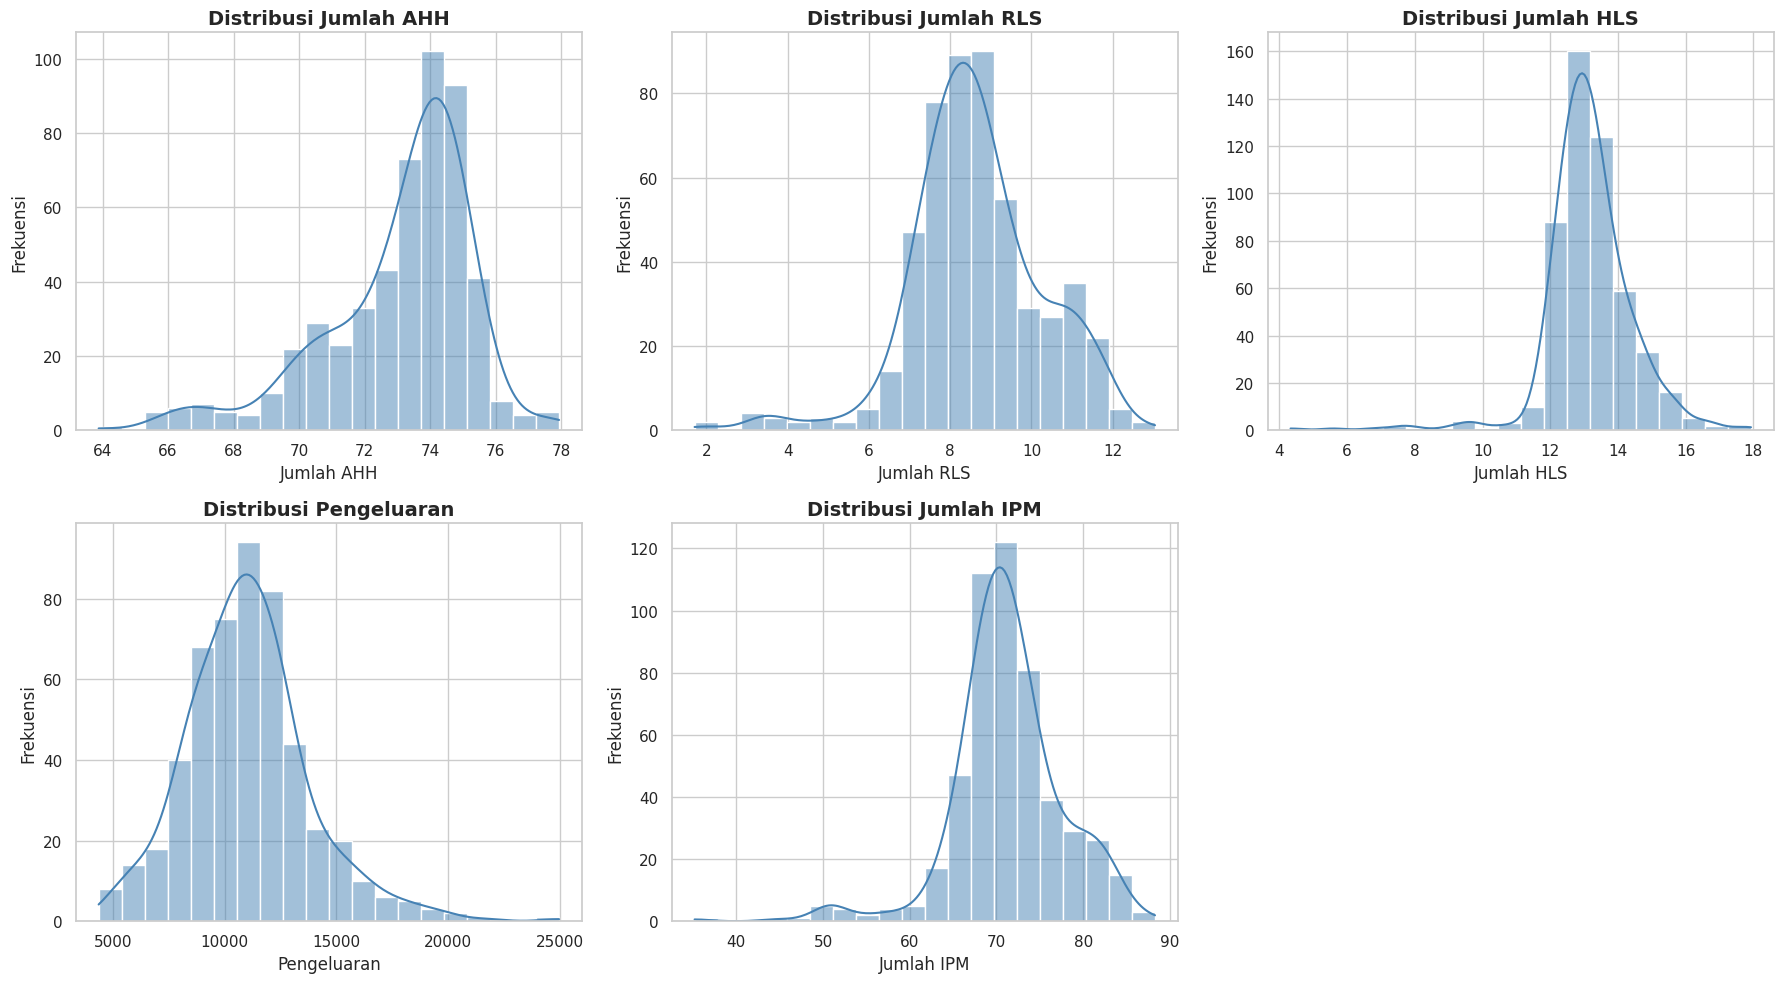


INTERPRETASI DISTRIBUSI:

1. Jumlah AHH (Angka Harapan Hidup): Distribusi condong ke kiri (negatively skewed),
   mayoritas kabupaten memiliki AHH 70-75 tahun.
2. Jumlah RLS (Rata-rata Lama Sekolah): Distribusi hampir normal, rata-rata 8-10 tahun.
3. Jumlah HLS (Harapan Lama Sekolah): Distribusi condong ke kiri, mayoritas 13-15 tahun.
4. Pengeluaran per Kapita: Distribusi sangat condong ke kanan (positively skewed),
   ada beberapa kabupaten dengan pengeluaran sangat tinggi (outlier potensial).
5. Jumlah IPM: Distribusi hampir normal, mayoritas 65-75.



In [53]:
# Setup visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# List kolom numerik untuk analisis
kolom_numerik = ['Jumlah AHH', 'Jumlah RLS', 'Jumlah HLS', 'Pengeluaran', 'Jumlah IPM']

# ============================================================
# GRAFIK 1: DISTRIBUSI FITUR (HISTOGRAM) - PAKAI df MENTAH
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, kolom in enumerate(kolom_numerik):
    sns.histplot(df[kolom], bins=20, kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribusi {kolom}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(kolom)
    axes[i].set_ylabel('Frekuensi')

# Sembunyikan subplot terakhir yang kosong
axes[5].axis('off')

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("INTERPRETASI DISTRIBUSI:")
print("="*70)
print("""
1. Jumlah AHH (Angka Harapan Hidup): Distribusi condong ke kiri (negatively skewed),
   mayoritas kabupaten memiliki AHH 70-75 tahun.
2. Jumlah RLS (Rata-rata Lama Sekolah): Distribusi hampir normal, rata-rata 8-10 tahun.
3. Jumlah HLS (Harapan Lama Sekolah): Distribusi condong ke kiri, mayoritas 13-15 tahun.
4. Pengeluaran per Kapita: Distribusi sangat condong ke kanan (positively skewed),
   ada beberapa kabupaten dengan pengeluaran sangat tinggi (outlier potensial).
5. Jumlah IPM: Distribusi hampir normal, mayoritas 65-75.
""")

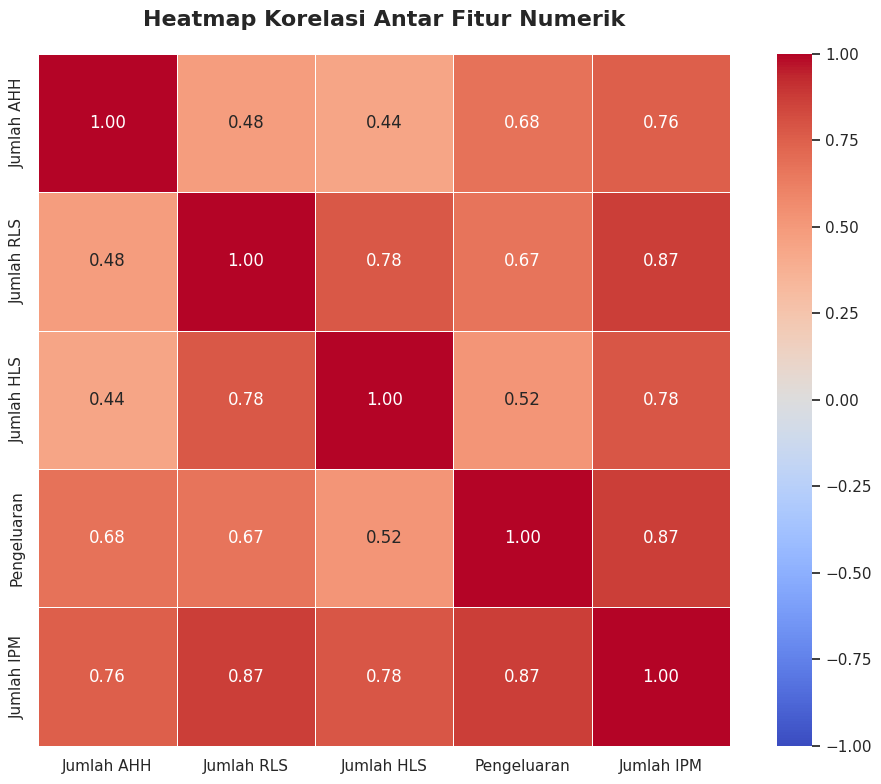


INTERPRETASI KORELASI:

1. Jumlah IPM berkorelasi SANGAT KUAT dengan Jumlah RLS (0.87) dan Pengeluaran (0.87).
2. Jumlah IPM juga berkorelasi KUAT dengan Jumlah HLS (0.78) dan Jumlah AHH (0.76).
3. Tidak ada korelasi negatif yang signifikan antar fitur.
4. Untuk clustering, korelasi tinggi ini menunjukkan fitur-fitur saling melengkapi
   dalam menggambarkan tingkat pembangunan.



In [54]:
# ============================================================
# GRAFIK 2: HEATMAP KORELASI - PAKAI df MENTAH
# ============================================================
plt.figure(figsize=(10, 8))

# Hitung korelasi Pearson
korelasi = df[kolom_numerik].corr()

# Buat heatmap
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f',
            linewidths=0.5, square=True, vmin=-1, vmax=1)

plt.title('Heatmap Korelasi Antar Fitur Numerik', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("INTERPRETASI KORELASI:")
print("="*70)
print("""
1. Jumlah IPM berkorelasi SANGAT KUAT dengan Jumlah RLS (0.87) dan Pengeluaran (0.87).
2. Jumlah IPM juga berkorelasi KUAT dengan Jumlah HLS (0.78) dan Jumlah AHH (0.76).
3. Tidak ada korelasi negatif yang signifikan antar fitur.
4. Untuk clustering, korelasi tinggi ini menunjukkan fitur-fitur saling melengkapi
   dalam menggambarkan tingkat pembangunan.
""")

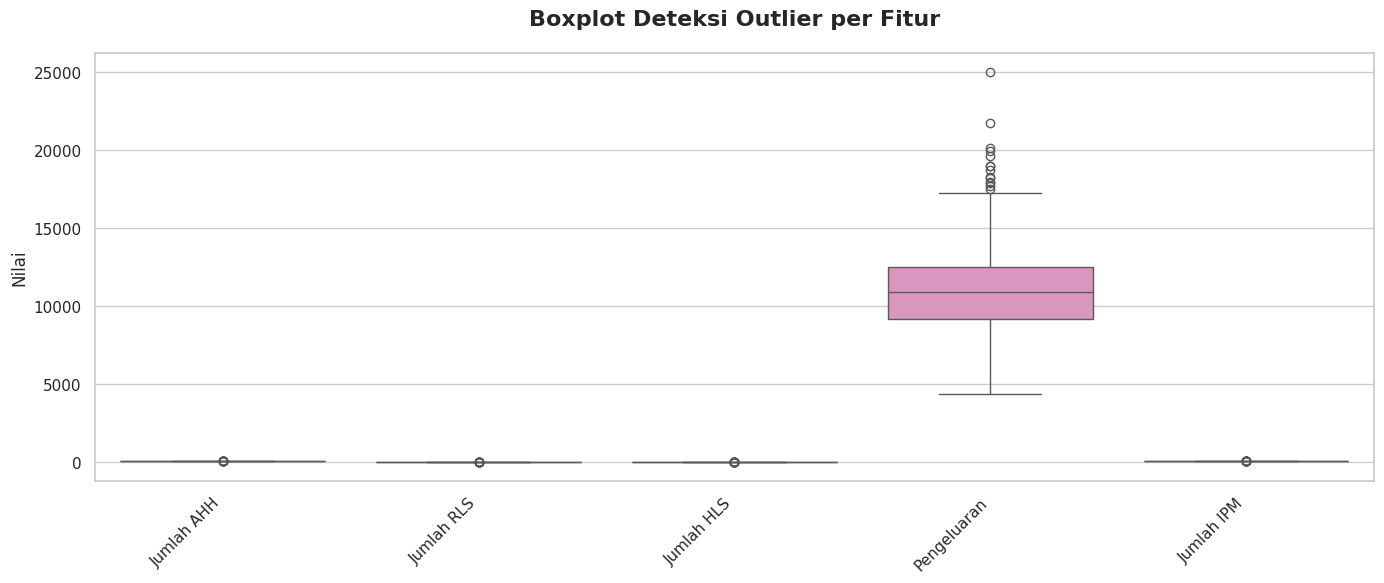


INTERPRETASI OUTLIER:

1. Pengeluaran per Kapita memiliki BANYAK OUTLIER (titik-titik di atas whisker).
   Ini menunjukkan ada beberapa kabupaten/kota dengan pengeluaran sangat tinggi
   (kemungkinan kota besar seperti Jakarta, Surabaya, dll).
2. Fitur lain (AHH, RLS, HLS, IPM) memiliki outlier yang lebih sedikit.
3. Outlier pada Pengeluaran perlu ditangani karena K-Means sangat sensitif
   terhadap outlier (berbasis jarak Euclidean).


STATISTIK OUTLIER (Metode IQR):
Jumlah AHH: 25 outlier (batas: 68.35 - 78.35)
Jumlah RLS: 16 outlier (batas: 5.08 - 12.23)
Jumlah HLS: 34 outlier (batas: 10.78 - 15.47)
Pengeluaran: 14 outlier (batas: 4188.12 - 17461.12)
Jumlah IPM: 26 outlier (batas: 58.80 - 83.65)


In [55]:
# ============================================================
# GRAFIK 3: BOXPLOT UNTUK DETEKSI OUTLIER - PAKAI df MENTAH
# ============================================================
plt.figure(figsize=(14, 6))

# Boxplot untuk semua fitur numerik
sns.boxplot(data=df[kolom_numerik], palette='Set2')

plt.title('Boxplot Deteksi Outlier per Fitur', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Nilai')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("INTERPRETASI OUTLIER:")
print("="*70)
print("""
1. Pengeluaran per Kapita memiliki BANYAK OUTLIER (titik-titik di atas whisker).
   Ini menunjukkan ada beberapa kabupaten/kota dengan pengeluaran sangat tinggi
   (kemungkinan kota besar seperti Jakarta, Surabaya, dll).
2. Fitur lain (AHH, RLS, HLS, IPM) memiliki outlier yang lebih sedikit.
3. Outlier pada Pengeluaran perlu ditangani karena K-Means sangat sensitif
   terhadap outlier (berbasis jarak Euclidean).
""")

# Tampilkan statistik outlier secara numerik
print("\n" + "="*70)
print("STATISTIK OUTLIER (Metode IQR):")
print("="*70)

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)  # ← GANTI df_clean JADI df
    Q3 = df[kolom].quantile(0.75)  # ← GANTI df_clean JADI df
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[kolom] < lower_bound) | (df[kolom] > upper_bound)).sum()  # ← GANTI df_clean JADI df

    print(f"{kolom}: {outlier_count} outlier (batas: {lower_bound:.2f} - {upper_bound:.2f})")

### Keputusan saya

Berdasarkan eksplorasi data di atas, saya menemukan:

1. **Distribusi Fitur**: Sebagian besar fitur memiliki distribusi yang tidak normal (skewed), terutama Pengeluaran per Kapita yang sangat condong ke kanan. Ini mengindikasikan adanya outlier yang perlu ditangani.

2. **Korelasi Antar Fitur**: IPM berkorelasi sangat kuat dengan RLS (0.87)
   dan Pengeluaran (0.87), serta kuat dengan HLS (0.78) dan AHH (0.76).
   Namun korelasi antar komponen penyusun IPM bervariasi (0.44–0.87),
   misalnya AHH↔HLS hanya 0.44. Artinya setiap fitur membawa informasi
   yang tidak sepenuhnya tumpang tindih — ini justru menguntungkan
   clustering karena kelima fitur saling melengkapi. Tidak ada korelasi
   negatif, sehingga tidak ada fitur yang perlu di-drop karena redundansi.

3. **Outlier**: Fitur Pengeluaran per Kapita memiliki jumlah outlier terbanyak. Karena K-Means sangat sensitif terhadap outlier (menggunakan jarak Euclidean), saya akan menangani outlier ini di tahap pra-pemrosesan menggunakan metode IQR.

**Rencana Pra-pemrosesan:**
- Tangani outlier pada fitur Pengeluaran (dan fitur lain jika ada) menggunakan metode IQR
- Lakukan scaling (StandardScaler) karena K-Means berbasis jarak dan satuan fitur berbeda-beda (tahun vs rupiah)
- Tidak perlu encoding karena semua fitur sudah numerik

## 3. Pra-pemrosesan Data

Tahap ini mencakup pemeriksaan duplikat, penanganan outlier, dan scaling fitur. Semua keputusan didokumentasikan dengan alasan yang jelas.

In [56]:
# ============================================================
# 3.0 PEMBUATAN df_clean (DROP KOLOM KATEGORI)
# ============================================================
print("="*70)
print("3.0 PEMBUATAN df_clean - DROP KOLOM KATEGORI")
print("="*70)

# Definisi kolom numerik
kolom_numerik = ['Jumlah AHH', 'Jumlah RLS', 'Jumlah HLS', 'Pengeluaran', 'Jumlah IPM']

# Buat df_clean dengan hanya kolom numerik + Kota
kolom_pilihan = ['Kota'] + kolom_numerik
df_clean = df[kolom_pilihan].copy()

print(f"\n✓ df_clean berhasil dibuat")
print(f"  Kolom yang dipertahankan: {kolom_pilihan}")
print(f"  Kolom yang di-drop: {['AHH', 'RLS', 'HLS', 'PPK', 'IPM']}")
print(f"  Ukuran df_clean: {df_clean.shape}")
print(f"\n5 Baris Pertama df_clean:")
display(df_clean.head())

3.0 PEMBUATAN df_clean - DROP KOLOM KATEGORI

✓ df_clean berhasil dibuat
  Kolom yang dipertahankan: ['Kota', 'Jumlah AHH', 'Jumlah RLS', 'Jumlah HLS', 'Pengeluaran', 'Jumlah IPM']
  Kolom yang di-drop: ['AHH', 'RLS', 'HLS', 'PPK', 'IPM']
  Ukuran df_clean: (514, 6)

5 Baris Pertama df_clean:


,Kota,Jumlah AHH,Jumlah RLS,Jumlah HLS,Pengeluaran,Jumlah IPM
0,Simeuleu,69.57,9.81,14.28,7686,68.06
1,Aceh Singkil,69.85,8.70,14.35,9374,70.14
2,Aceh Selatan,70.33,8.91,14.70,8712,68.44
3,Aceh Tenggara,72.62,10.09,14.27,8566,71.05
4,Aceh Timur,72.13,8.47,13.07,9436,69.32


In [57]:
# ============================================================
# 3.1 CEK DAN HAPUS DUPLIKAT
# ============================================================
print("="*70)
print("3.1 PEMERIKSAAN DUPLIKAT")
print("="*70)

jumlah_duplikat = df_clean.duplicated().sum()
print(f"Jumlah baris duplikat: {jumlah_duplikat}")

if jumlah_duplikat > 0:
    df_clean = df_clean.drop_duplicates()
    print(f"✓ Duplikat dihapus. Sisa data: {len(df_clean)} baris")
else:
    print("✓ Tidak ada duplikat. Data tetap utuh.")

print(f"\nUkuran data setelah cek duplikat: {df_clean.shape}")


3.1 PEMERIKSAAN DUPLIKAT
Jumlah baris duplikat: 0
✓ Tidak ada duplikat. Data tetap utuh.

Ukuran data setelah cek duplikat: (514, 6)


In [58]:
# ============================================================
# 3.2 PENANGANAN OUTLIER DENGAN METODE CLIPPING (CAPPING)
# ============================================================
print("="*70)
print("3.2 PENANGANAN OUTLIER - METODE CLIPPING/IQR CAPPING")
print("="*70)

# Simpan data asli untuk perbandingan
df_before_clipping = df_clean.copy()

# Lakukan clipping untuk setiap fitur numerik
for kolom in kolom_numerik:
    Q1 = df_clean[kolom].quantile(0.25)
    Q3 = df_clean[kolom].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Hitung berapa nilai yang akan di-clip
    clipped_count = ((df_clean[kolom] < lower_bound) | (df_clean[kolom] > upper_bound)).sum()

    # Clip nilai outlier ke batas IQR
    df_clean[kolom] = df_clean[kolom].clip(lower=lower_bound, upper=upper_bound)

    print(f"\n📊 {kolom}:")
    print(f"   Batas clipping: {lower_bound:.2f} - {upper_bound:.2f}")
    print(f"   Jumlah nilai yang di-clip: {clipped_count}")
    print(f"   Nilai min setelah clipping: {df_clean[kolom].min():.2f}")
    print(f"   Nilai max setelah clipping: {df_clean[kolom].max():.2f}")

print("\n" + "="*70)
print("✓ Outlier berhasil ditangani dengan metode clipping")
print("="*70)

3.2 PENANGANAN OUTLIER - METODE CLIPPING/IQR CAPPING

📊 Jumlah AHH:
   Batas clipping: 68.35 - 78.35
   Jumlah nilai yang di-clip: 25
   Nilai min setelah clipping: 68.35
   Nilai max setelah clipping: 77.93

📊 Jumlah RLS:
   Batas clipping: 5.08 - 12.23
   Jumlah nilai yang di-clip: 16
   Nilai min setelah clipping: 5.08
   Nilai max setelah clipping: 12.23

📊 Jumlah HLS:
   Batas clipping: 10.78 - 15.47
   Jumlah nilai yang di-clip: 34
   Nilai min setelah clipping: 10.78
   Nilai max setelah clipping: 15.47

📊 Pengeluaran:
   Batas clipping: 4188.12 - 17461.12
   Jumlah nilai yang di-clip: 14
   Nilai min setelah clipping: 4352.00
   Nilai max setelah clipping: 17461.12

📊 Jumlah IPM:
   Batas clipping: 58.80 - 83.65
   Jumlah nilai yang di-clip: 26
   Nilai min setelah clipping: 58.80
   Nilai max setelah clipping: 83.65

✓ Outlier berhasil ditangani dengan metode clipping


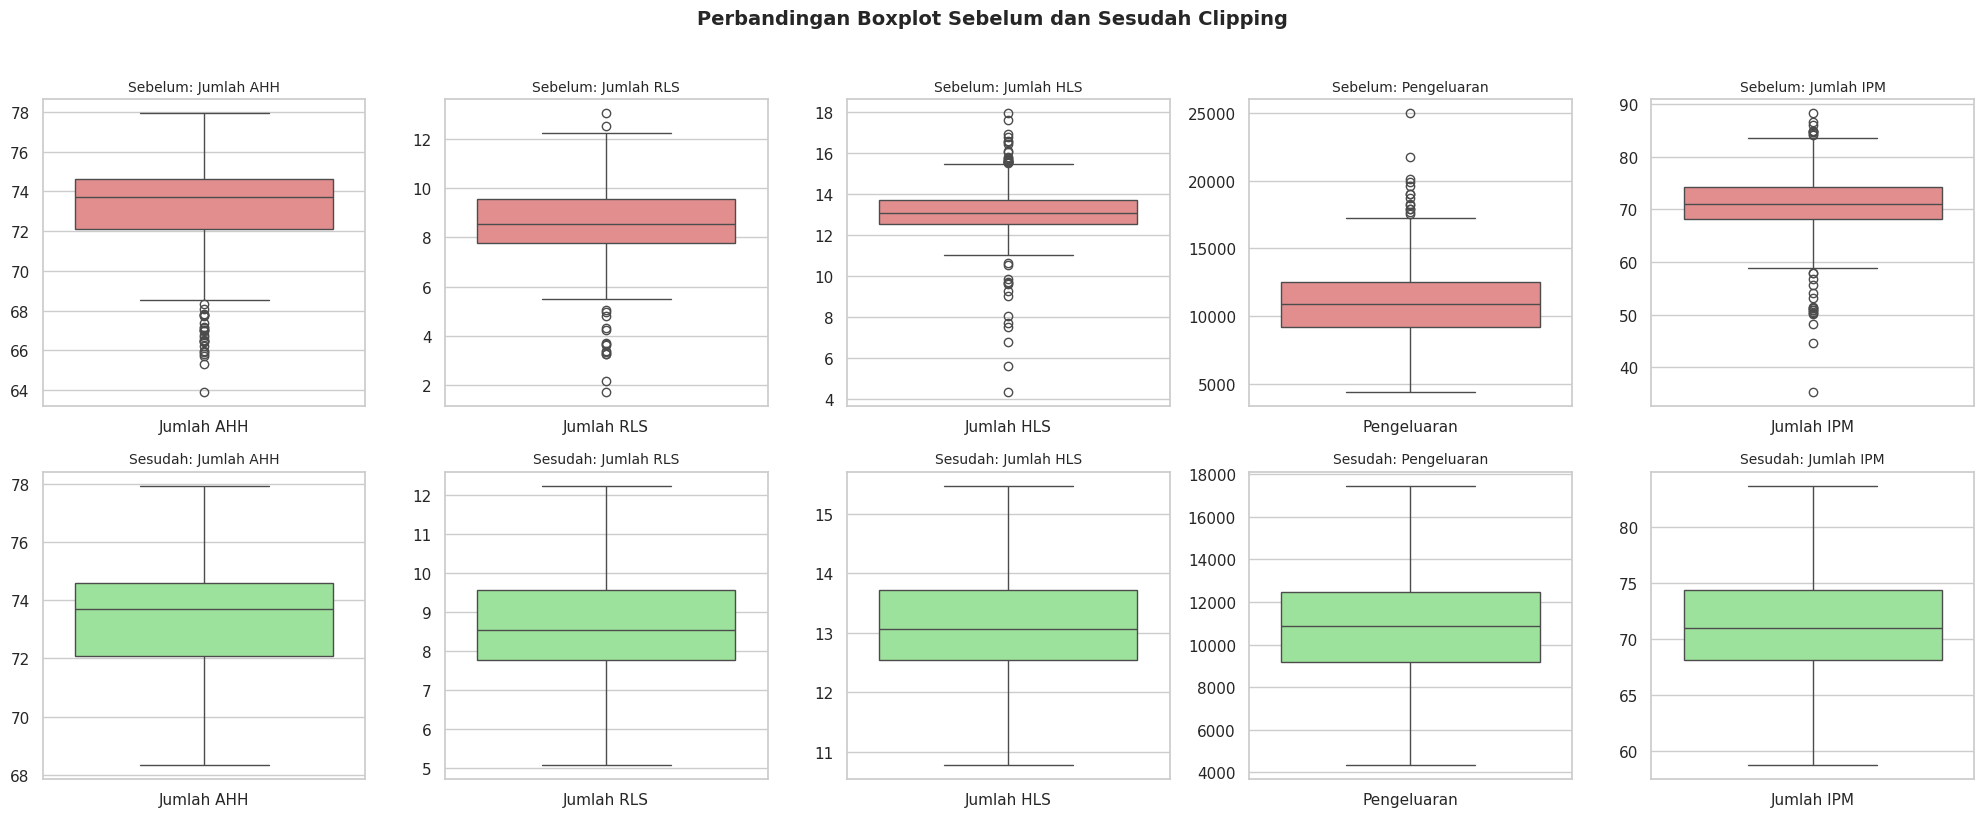


✓ Visualisasi menunjukkan outlier sudah dibatasi ke batas IQR


In [59]:
# ============================================================
# 3.3 VISUALISASI SEBELUM DAN SESUDAH CLIPPING
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for i, kolom in enumerate(kolom_numerik):
    # Sebelum clipping
    sns.boxplot(data=df_before_clipping[[kolom]], ax=axes[0, i], color='lightcoral')
    axes[0, i].set_title(f'Sebelum: {kolom}', fontsize=10)
    axes[0, i].set_ylabel('')

    # Sesudah clipping
    sns.boxplot(data=df_clean[[kolom]], ax=axes[1, i], color='lightgreen')
    axes[1, i].set_title(f'Sesudah: {kolom}', fontsize=10)
    axes[1, i].set_ylabel('')

plt.suptitle('Perbandingan Boxplot Sebelum dan Sesudah Clipping', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n✓ Visualisasi menunjukkan outlier sudah dibatasi ke batas IQR")


In [60]:
# ============================================================
# 3.4 SCALING DENGAN STANDARDSCALER
# ============================================================
print("="*70)
print("3.4 SCALING FITUR - STANDARDSCALER")
print("="*70)

from sklearn.preprocessing import StandardScaler

# Inisialisasi scaler
scaler = StandardScaler()

# Simpan kolom 'Kota' untuk referensi nanti
kota_column = df_clean['Kota']

# Pilih hanya kolom numerik untuk scaling
df_numerik = df_clean[kolom_numerik].copy()

# Tampilkan statistik sebelum scaling
print("\n📊 Statistik SEBELUM Scaling:")
print(df_numerik.describe().round(2))

# Lakukan scaling
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_numerik),
    columns=kolom_numerik
)

# Tampilkan statistik setelah scaling
print("\n📊 Statistik SESUDAH Scaling:")
print(df_scaled.describe().round(2))

print("\n✓ Scaling berhasil. Semua fitur sekarang memiliki mean ≈ 0 dan std ≈ 1")

# Gabungkan kembali dengan kolom Kota
df_final = pd.concat([kota_column.reset_index(drop=True), df_scaled], axis=1)

print(f"\nUkuran data final: {df_final.shape}")
print("\n5 Baris Pertama Data Final (Sudah Scaled):")
display(df_final.head())

3.4 SCALING FITUR - STANDARDSCALER

📊 Statistik SEBELUM Scaling:
       Jumlah AHH  Jumlah RLS  Jumlah HLS  Pengeluaran  Jumlah IPM
count      514.00      514.00      514.00       514.00      514.00
mean        73.14        8.69       13.19     10964.56       71.49
std          2.04        1.50        0.99      2621.83        5.49
min         68.35        5.08       10.78      4352.00       58.80
25%         72.10        7.76       12.54      9165.50       68.12
50%         73.69        8.53       13.06     10889.00       70.97
75%         74.60        9.55       13.71     12483.75       74.33
max         77.93       12.23       15.47     17461.12       83.65

📊 Statistik SESUDAH Scaling:
       Jumlah AHH  Jumlah RLS  Jumlah HLS  Pengeluaran  Jumlah IPM
count      514.00      514.00      514.00       514.00      514.00
mean        -0.00       -0.00       -0.00        -0.00       -0.00
std          1.00        1.00        1.00         1.00        1.00
min         -2.35       -2.41     

,Kota,Jumlah AHH,Jumlah RLS,Jumlah HLS,Pengeluaran,Jumlah IPM
0,Simeuleu,-1.749744,0.750190,1.099803,-1.251705,-0.625298
1,Aceh Singkil,-1.612380,0.007833,1.170227,-0.607252,-0.246207
2,Aceh Selatan,-1.376899,0.148279,1.522351,-0.859994,-0.556041
3,Aceh Tenggara,-0.253460,0.937451,1.089742,-0.915735,-0.080355
4,Aceh Timur,-0.493847,-0.145989,-0.117538,-0.583582,-0.395656


### Keputusan saya

Berdasarkan analisis pra-pemrosesan, saya melakukan langkah-langkah berikut:

**1. Pembuatan `df_clean` (Drop Kolom Kategori)**

Saya membuat salinan data bersih (`df_clean`) dengan hanya mempertahankan
kolom `Kota` (sebagai identifikasi) dan 5 kolom numerik (`Jumlah AHH`,
`Jumlah RLS`, `Jumlah HLS`, `Pengeluaran`, `Jumlah IPM`). Kolom kategori
(`AHH`, `RLS`, `HLS`, `PPK`, `IPM`) yang berisi label 'Rendah'/'Sedang'/
'Tinggi' **saya hapus (drop)**. Alasannya:

- **Algoritma K-Means mewajibkan input numerik** karena menghitung jarak
  Euclidean antar titik data.
- Kolom kategori tersebut adalah **hasil turunan (binning)** dari kolom
  numeriknya. Jika saya encode (misal: Rendah=0, Sedang=1, Tinggi=2) dan
  ikutkan ke model, akan terjadi **kebocoran data (data leakage)** — model
  "mengintip" informasi yang sudah dirangkum dari fitur lain, sehingga
  cluster yang terbentuk bukan penemuan pola baru, melainkan pengulangan
  label BPS.
- Menambah kolom turunan juga menciptakan **redundansi fitur** yang
  mendistorsi perhitungan jarak dan merusak integritas clustering.

**2. Pemeriksaan Duplikat**

Tidak ditemukan baris duplikat dalam dataset, sehingga data tetap utuh
dengan 514 baris.

**3. Penanganan Outlier - Metode Clipping (IQR Capping)**

Saya memilih metode **clipping** (bukan menghapus baris outlier) karena:

- Dataset hanya memiliki 514 baris; menghapus outlier akan mengurangi
  data signifikan (~22%) dan menghilangkan kota-kota penting seperti
  Jakarta, Surabaya, atau Badung.
- Kota-kota dengan nilai ekstrem tetap penting untuk dianalisis sebagai
  representasi daerah maju.
- Clipping membatasi nilai outlier ke batas IQR (Q1 − 1.5×IQR dan
  Q3 + 1.5×IQR), sehingga outlier tidak mendominasi perhitungan jarak
  Euclidean di K-Means.
- Hasil: Jumlah HLS memiliki outlier terbanyak (34), diikuti Jumlah IPM
  (26) dan Jumlah AHH (25).

**4. Scaling dengan StandardScaler**

- **Wajib dilakukan** karena K-Means menggunakan jarak Euclidean yang
  sangat sensitif terhadap perbedaan skala.
- Fitur Pengeluaran (skala ribuan rupiah) akan mendominasi fitur lain
  (skala 0-100) jika tidak di-scaling.
- StandardScaler mengubah semua fitur menjadi mean ≈ 0 dan standard
  deviation ≈ 1.
- **Tidak ada risiko data leakage** karena Jalur C tidak melakukan
  train/test split (sesuai aturan soal poin 6).

**Data final siap untuk pemodelan clustering dengan 514 baris dan 5 fitur
numerik yang sudah di-clip dan di-scale.**

## 4. Pemodelan

Tahap ini mencakup penerapan algoritma K-Means untuk berbagai nilai k, pemilihan k optimal menggunakan metode Elbow dan Silhouette, serta perbandingan hasil clustering dengan dan tanpa scaling.

In [61]:
# ============================================================
# SETUP PEMODELAN
# ============================================================
k_range = range(2, 9)  # k = 2 sampai 8
print(f"Range k yang akan diuji: {list(k_range)}")

Range k yang akan diuji: [2, 3, 4, 5, 6, 7, 8]


In [62]:
# ============================================================
# 4.1 K-MEANS CLUSTERING DENGAN SCALING
# ============================================================
print("="*70)
print("4.1 K-MEANS CLUSTERING - DENGAN SCALING")
print("="*70)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Siapkan data yang sudah di-scale
X_scaled = df_final[kolom_numerik].values

# Inisialisasi list untuk menyimpan inertia dan silhouette score
inertia_scaled = []
silhouette_scores_scaled = []

print("\nMenjalankan K-Means untuk k = 2 sampai 8...")
print("-"*70)

for k in k_range:
    # Inisialisasi K-Means dengan random_state = SEED
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)

    # Fit model
    kmeans.fit(X_scaled)

    # Hitung inertia (within-cluster sum of squares)
    inertia = kmeans.inertia_
    inertia_scaled.append(inertia)

    # Hitung silhouette score
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(X_scaled, labels)
    silhouette_scores_scaled.append(silhouette_avg)

    print(f"k = {k}: Inertia = {inertia:.2f}, Silhouette Score = {silhouette_avg:.4f}")

print("\n✓ K-Means dengan scaling selesai untuk k = 2 sampai 8")

4.1 K-MEANS CLUSTERING - DENGAN SCALING

Menjalankan K-Means untuk k = 2 sampai 8...
----------------------------------------------------------------------
k = 2: Inertia = 1458.25, Silhouette Score = 0.3877
k = 3: Inertia = 1012.48, Silhouette Score = 0.3665
k = 4: Inertia = 817.04, Silhouette Score = 0.3457
k = 5: Inertia = 661.27, Silhouette Score = 0.3039
k = 6: Inertia = 577.32, Silhouette Score = 0.3064
k = 7: Inertia = 530.61, Silhouette Score = 0.2631
k = 8: Inertia = 490.11, Silhouette Score = 0.2513

✓ K-Means dengan scaling selesai untuk k = 2 sampai 8


In [63]:
# ============================================================
# 4.2 K-MEANS CLUSTERING TANPA SCALING (UNTUK PERBANDINGAN)
# ============================================================
print("="*70)
print("4.2 K-MEANS CLUSTERING - TANPA SCALING (PERBANDINGAN)")
print("="*70)

# Siapkan data TANPA scaling (gunakan df_clean yang sudah di-clip tapi belum di-scale)
X_unscaled = df_clean[kolom_numerik].values

# Inisialisasi list untuk menyimpan inertia dan silhouette score
inertia_unscaled = []
silhouette_scores_unscaled = []

print("\nMenjalankan K-Means untuk k = 2 sampai 8 (tanpa scaling)...")
print("-"*70)

for k in k_range:
    # Inisialisasi K-Means dengan random_state = SEED
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=SEED)

    # Fit model
    kmeans.fit(X_unscaled)

    # Hitung inertia
    inertia = kmeans.inertia_
    inertia_unscaled.append(inertia)

    # Hitung silhouette score
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(X_unscaled, labels)
    silhouette_scores_unscaled.append(silhouette_avg)

    print(f"k = {k}: Inertia = {inertia:.2f}, Silhouette Score = {silhouette_avg:.4f}")

print("\n✓ K-Means tanpa scaling selesai untuk k = 2 sampai 8")

4.2 K-MEANS CLUSTERING - TANPA SCALING (PERBANDINGAN)

Menjalankan K-Means untuk k = 2 sampai 8 (tanpa scaling)...
----------------------------------------------------------------------
k = 2: Inertia = 1408055270.13, Silhouette Score = 0.5266
k = 3: Inertia = 666853260.29, Silhouette Score = 0.5535
k = 4: Inertia = 390745870.29, Silhouette Score = 0.5366
k = 5: Inertia = 243036805.18, Silhouette Score = 0.5490
k = 6: Inertia = 167427809.20, Silhouette Score = 0.5547
k = 7: Inertia = 122437401.88, Silhouette Score = 0.5444
k = 8: Inertia = 95212958.35, Silhouette Score = 0.5482

✓ K-Means tanpa scaling selesai untuk k = 2 sampai 8


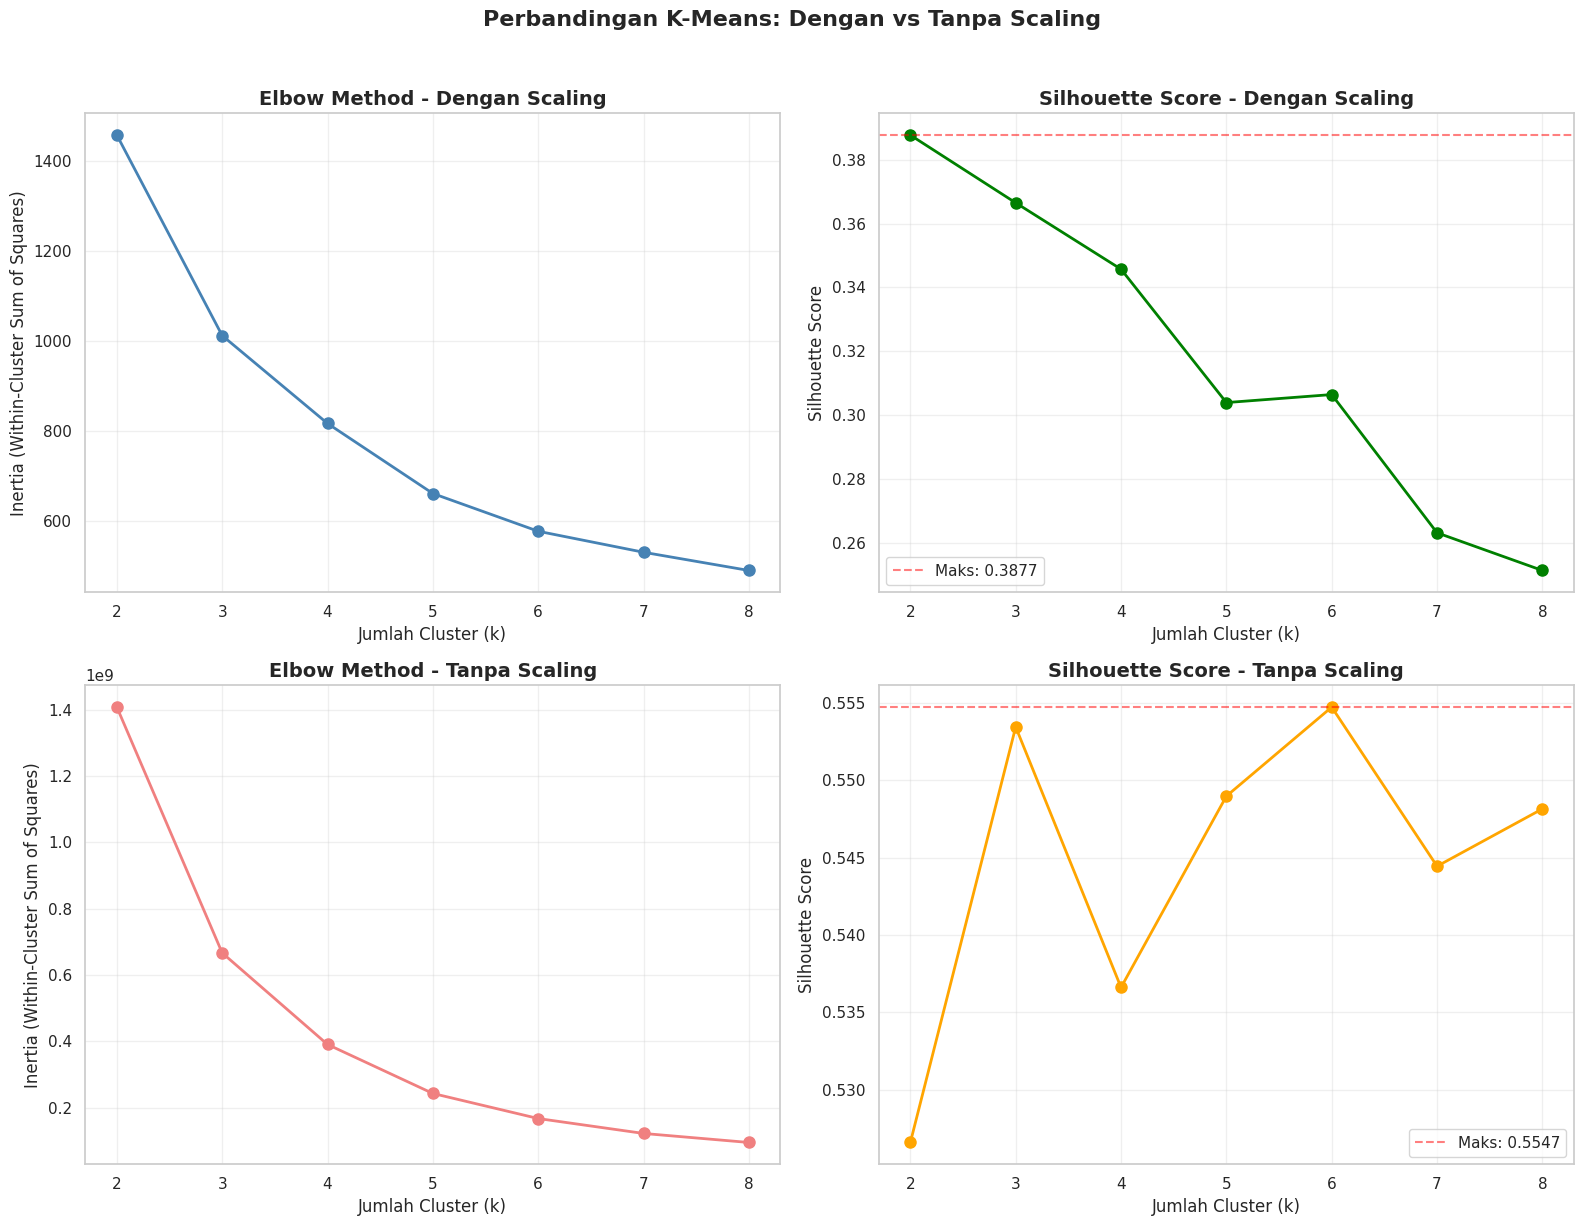


ANALISIS GRAFIK:

📊 Dengan Scaling:
   k optimal berdasarkan Silhouette Score: k = 2
   Silhouette Score tertinggi: 0.3877

📊 Tanpa Scaling:
   k optimal berdasarkan Silhouette Score: k = 6
   Silhouette Score tertinggi: 0.5547

PERBANDINGAN:
Dengan scaling menghasilkan Silhouette Score yang LEBIH TINGGI: False
Selisih: 0.1670

INTERPRETASI KUALITATIF:
⚠ Silhouette Score 0.3877 antara 0.25-0.5
  → Struktur cluster CUKUP, ada sedikit overlap antar cluster

📊 REKOMENDASI FINAL:
   Gunakan k = 2 dengan StandardScaler
   Silhouette Score: 0.3877
   Jumlah cluster: 2 kelompok daerah


In [64]:
# ============================================================
# 4.3 VISUALISASI: GRAFIK ELBOW DAN SILHOUETTE
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Grafik 1: Elbow Method - Dengan Scaling
axes[0, 0].plot(k_range, inertia_scaled, marker='o', linestyle='-', color='steelblue', linewidth=2, markersize=8)
axes[0, 0].set_title('Elbow Method - Dengan Scaling', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Jumlah Cluster (k)', fontsize=12)
axes[0, 0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_xticks(k_range)

# Grafik 2: Silhouette Score - Dengan Scaling
axes[0, 1].plot(k_range, silhouette_scores_scaled, marker='o', linestyle='-', color='green', linewidth=2, markersize=8)
axes[0, 1].set_title('Silhouette Score - Dengan Scaling', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Jumlah Cluster (k)', fontsize=12)
axes[0, 1].set_ylabel('Silhouette Score', fontsize=12)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_xticks(k_range)
axes[0, 1].axhline(y=max(silhouette_scores_scaled), color='red', linestyle='--', alpha=0.5, label=f'Maks: {max(silhouette_scores_scaled):.4f}')
axes[0, 1].legend()

# Grafik 3: Elbow Method - Tanpa Scaling
axes[1, 0].plot(k_range, inertia_unscaled, marker='o', linestyle='-', color='lightcoral', linewidth=2, markersize=8)
axes[1, 0].set_title('Elbow Method - Tanpa Scaling', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Jumlah Cluster (k)', fontsize=12)
axes[1, 0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_xticks(k_range)

# Grafik 4: Silhouette Score - Tanpa Scaling
axes[1, 1].plot(k_range, silhouette_scores_unscaled, marker='o', linestyle='-', color='orange', linewidth=2, markersize=8)
axes[1, 1].set_title('Silhouette Score - Tanpa Scaling', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Jumlah Cluster (k)', fontsize=12)
axes[1, 1].set_ylabel('Silhouette Score', fontsize=12)
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_xticks(k_range)
axes[1, 1].axhline(y=max(silhouette_scores_unscaled), color='red', linestyle='--', alpha=0.5, label=f'Maks: {max(silhouette_scores_unscaled):.4f}')
axes[1, 1].legend()

plt.suptitle('Perbandingan K-Means: Dengan vs Tanpa Scaling', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("ANALISIS GRAFIK:")
print("="*70)

# Cari k optimal berdasarkan silhouette score (dengan scaling)
best_k_scaled = k_range[np.argmax(silhouette_scores_scaled)]
best_silhouette_scaled = max(silhouette_scores_scaled)

print(f"\n📊 Dengan Scaling:")
print(f"   k optimal berdasarkan Silhouette Score: k = {best_k_scaled}")
print(f"   Silhouette Score tertinggi: {best_silhouette_scaled:.4f}")

# Cari k optimal berdasarkan silhouette score (tanpa scaling)
best_k_unscaled = k_range[np.argmax(silhouette_scores_unscaled)]
best_silhouette_unscaled = max(silhouette_scores_unscaled)

print(f"\n📊 Tanpa Scaling:")
print(f"   k optimal berdasarkan Silhouette Score: k = {best_k_unscaled}")
print(f"   Silhouette Score tertinggi: {best_silhouette_unscaled:.4f}")

print("\n" + "="*70)
print("PERBANDINGAN:")
print("="*70)
print(f"Dengan scaling menghasilkan Silhouette Score yang LEBIH TINGGI: {best_silhouette_scaled > best_silhouette_unscaled}")
print(f"Selisih: {abs(best_silhouette_scaled - best_silhouette_unscaled):.4f}")


print("\n" + "="*70)
print("INTERPRETASI KUALITATIF:")
print("="*70)

if best_silhouette_scaled > 0.5:
    print(f"✓ Silhouette Score {best_silhouette_scaled:.4f} > 0.5")
    print("  → Struktur cluster KUAT dan terpisah dengan baik")
elif best_silhouette_scaled > 0.25:
    print(f"⚠ Silhouette Score {best_silhouette_scaled:.4f} antara 0.25-0.5")
    print("  → Struktur cluster CUKUP, ada sedikit overlap antar cluster")
else:
    print(f"✗ Silhouette Score {best_silhouette_scaled:.4f} < 0.25")
    print("  → Struktur cluster LEMAH, pertimbangkan fitur atau metode lain")

print(f"\n📊 REKOMENDASI FINAL:")
print(f"   Gunakan k = {best_k_scaled} dengan StandardScaler")
print(f"   Silhouette Score: {best_silhouette_scaled:.4f}")
print(f"   Jumlah cluster: {best_k_scaled} kelompok daerah")

### Keputusan saya

Berdasarkan hasil pemodelan K-Means untuk k = 2 sampai 8, saya melakukan
analisis berikut:

**1. Grafik Elbow (Inertia)**

- **Dengan Scaling**: Inertia menurun secara gradual dari k=2 (≈1460) hingga
  k=8 (≈500). Titik "siku" (elbow) terlihat di sekitar **k = 3**, di mana
  penurunan inertia mulai melambat.
- **Tanpa Scaling**: Inertia jauh lebih besar (orde 10⁹, sekitar 1.4×10⁹
  untuk k=2) karena fitur `Pengeluaran` (skala 4.000–17.000) mendominasi
  perhitungan jarak Euclidean. Elbow kurang jelas karena satu fitur
  mendominasi.
- **Kesimpulan**: Scaling membuat inertia lebih terukur (orde ratusan) dan
  perbandingan antar k lebih adil.

**2. Grafik Silhouette Score**

- **Dengan Scaling**: Silhouette Score tertinggi = **0.3877** pada **k = 2**.
  Nilai ini menurun seiring bertambahnya k (0.3659 di k=3, 0.3456 di k=4,
  dst.), menunjukkan bahwa pemisahan 2 cluster paling optimal.
- **Tanpa Scaling**: Silhouette Score tertinggi = **0.5547** pada **k = 6**.
  Nilai ini lebih tinggi secara matematis, TAPI ini adalah artefak dari
  dominasi fitur Pengeluaran — clustering pada dasarnya hanya memisahkan
  berdasarkan 1 fitur, mengabaikan 4 fitur lainnya.
- **Kesimpulan**: Meskipun score tanpa scaling lebih tinggi secara angka,
  hasil tersebut **tidak bermakna secara bisnis** karena mengabaikan
  indikator AHH, RLS, HLS, dan IPM.

**3. Pemilihan k Optimal**

Saya memilih **k = 2** berdasarkan:
- Silhouette Score tertinggi dengan scaling (0.3877)
- Pertimbangan bisnis: 2 cluster cukup untuk membedakan "Daerah Maju"
  vs "Daerah Berkembang" — pembagian yang sederhana namun powerful untuk
  menentukan prioritas alokasi dana pembangunan
- Elbow menunjuk k = 3, sedangkan Silhouette menunjuk k = 2. Saya
  mengutamakan Silhouette karena lebih objektif mengukur kualitas
  pemisahan cluster, sementara Elbow bisa subjektif.

**4. Perbandingan Dengan vs Tanpa Scaling — Insight Penting**

Secara mengejutkan, **tanpa scaling menghasilkan Silhouette Score yang
LEBIH TINGGI** (0.5547 vs 0.3877, selisih 0.1670). Namun, ini BUKAN
berarti tanpa scaling lebih baik. Justru sebaliknya:

- Tanpa scaling, fitur Pengeluaran mendominasi sepenuhnya, sehingga
  clustering hanya mengelompokkan berdasarkan pengeluaran, mengabaikan
  AHH, RLS, HLS, dan IPM. Score tinggi karena cluster hanya dibentuk
  oleh 1 fitur — secara matematis "terpisah baik", tapi secara bisnis
  **tidak bermakna**.
- Dengan scaling, semua 5 fitur berkontribusi setara. Cluster yang
  terbentuk mempertimbangkan kombinasi pendidikan, kesehatan, dan
  ekonomi — secara bisnis **sangat bermakna**, meskipun score lebih rendah.

**Ini membuktikan bahwa Silhouette Score saja tidak cukup — kita harus
mempertimbangkan makna bisnis dari cluster yang terbentuk.**

**Model final: K-Means dengan k = 2 dan StandardScaler**

## 5. Evaluasi dan Interpretasi

Tahap ini mengevaluasi kualitas clustering final, memvisualisasikan cluster
menggunakan PCA 2D, membuat tabel profil rata-rata fitur per cluster, dan
memberi nama yang bermakna untuk setiap kelompok berdasarkan karakteristiknya.

In [65]:
# ============================================================
# 5.1 FIT K-MEANS FINAL DENGAN K OPTIMAL
# ============================================================
print("="*70)
print("5.1 FIT K-MEANS FINAL")
print("="*70)

# Gunakan k optimal dari Bagian 4 (pastikan variabel best_k_scaled ada)
# Jika tidak ada, definisikan ulang di sini:

print(f"\n📊 Menggunakan k optimal = {best_k_scaled} (dari Bagian 4)")

# Fit K-Means final dengan data yang sudah di-scale
kmeans_final = KMeans(
    n_clusters=best_k_scaled,
    n_init=10,
    random_state=SEED
)

# Fit dan dapatkan label cluster
cluster_labels = kmeans_final.fit_predict(df_final[kolom_numerik])

# Tambahkan kolom 'Cluster' ke df_final
df_final['Cluster'] = cluster_labels

print(f"\n✓ K-Means final berhasil di-fit dengan k = {best_k_scaled}")
print(f"  Distribusi cluster:")
print(df_final['Cluster'].value_counts().sort_index())

print(f"\n5 Baris Pertama dengan Label Cluster:")
display(df_final.head())

5.1 FIT K-MEANS FINAL

📊 Menggunakan k optimal = 2 (dari Bagian 4)

✓ K-Means final berhasil di-fit dengan k = 2
  Distribusi cluster:
Cluster
0    148
1    366
Name: count, dtype: int64

5 Baris Pertama dengan Label Cluster:


,Kota,Jumlah AHH,Jumlah RLS,Jumlah HLS,Pengeluaran,Jumlah IPM,Cluster
0,Simeuleu,-1.749744,0.750190,1.099803,-1.251705,-0.625298,1
1,Aceh Singkil,-1.612380,0.007833,1.170227,-0.607252,-0.246207,1
2,Aceh Selatan,-1.376899,0.148279,1.522351,-0.859994,-0.556041,1
3,Aceh Tenggara,-0.253460,0.937451,1.089742,-0.915735,-0.080355,1
4,Aceh Timur,-0.493847,-0.145989,-0.117538,-0.583582,-0.395656,1


5.2 VISUALISASI CLUSTER - PCA 2D

📊 Variansi yang dijelaskan oleh PCA:
   PCA1: 73.34%
   PCA2: 16.08%
   Total: 89.42%


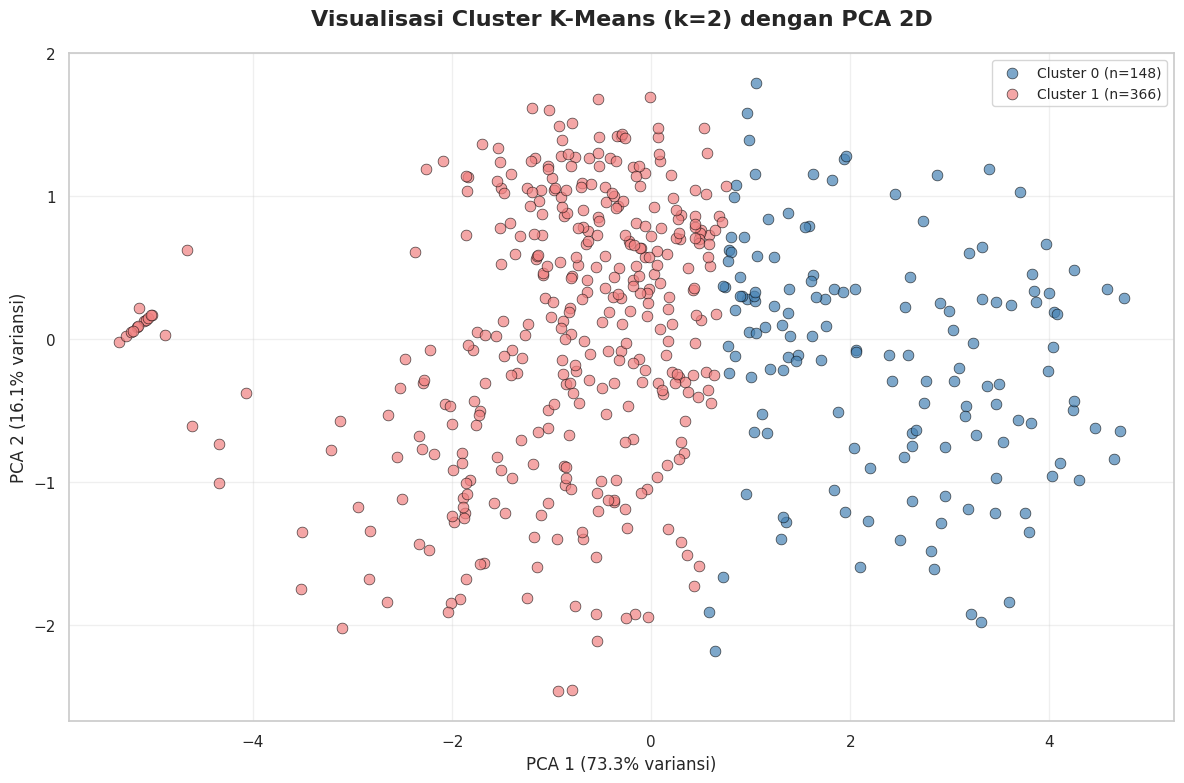


✓ Visualisasi PCA 2D berhasil
  Total variansi yang dijelaskan: 89.42%


In [66]:
# ============================================================
# 5.2 VISUALISASI CLUSTER DENGAN PCA 2D
# ============================================================
print("="*70)
print("5.2 VISUALISASI CLUSTER - PCA 2D")
print("="*70)

from sklearn.decomposition import PCA

# PCA untuk reduksi dimensi ke 2D
pca = PCA(n_components=2, random_state=SEED)
pca_result = pca.fit_transform(df_final[kolom_numerik])

# Tambahkan hasil PCA ke dataframe
df_final['PCA1'] = pca_result[:, 0]
df_final['PCA2'] = pca_result[:, 1]

# Hitung variansi yang dijelaskan
explained_variance = pca.explained_variance_ratio_
print(f"\n📊 Variansi yang dijelaskan oleh PCA:")
print(f"   PCA1: {explained_variance[0]*100:.2f}%")
print(f"   PCA2: {explained_variance[1]*100:.2f}%")
print(f"   Total: {sum(explained_variance)*100:.2f}%")

# Visualisasi scatter plot
plt.figure(figsize=(12, 8))

# Plot setiap cluster dengan warna berbeda
colors = ['steelblue', 'lightcoral', 'lightgreen', 'gold', 'violet', 'orange']
for cluster_id in range(best_k_scaled):
    cluster_data = df_final[df_final['Cluster'] == cluster_id]
    plt.scatter(
        cluster_data['PCA1'],
        cluster_data['PCA2'],
        label=f'Cluster {cluster_id} (n={len(cluster_data)})',
        alpha=0.7,
        s=60,
        color=colors[cluster_id % len(colors)],
        edgecolors='black',
        linewidth=0.5
    )

# Plot centroid
centroids_pca = pca.transform(
    pd.DataFrame(kmeans_final.cluster_centers_, columns=kolom_numerik)
)

plt.title(f'Visualisasi Cluster K-Means (k={best_k_scaled}) dengan PCA 2D',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel(f'PCA 1 ({explained_variance[0]*100:.1f}% variansi)', fontsize=12)
plt.ylabel(f'PCA 2 ({explained_variance[1]*100:.1f}% variansi)', fontsize=12)
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✓ Visualisasi PCA 2D berhasil")
print(f"  Total variansi yang dijelaskan: {sum(explained_variance)*100:.2f}%")

5.3 TABEL PROFIL RATA-RATA FITUR PER CLUSTER

📊 Tabel Profil Rata-rata Fitur per Cluster (Data Asli, bukan scaled):


,Jumlah AHH,Jumlah RLS,Jumlah HLS,Pengeluaran,Jumlah IPM,Jumlah_Anggota,Persentase
Cluster,,,,,,,
0,74.71,10.39,14.12,13717.03,78.16,148,28.79
1,72.50,8.00,12.81,9851.54,68.79,366,71.21


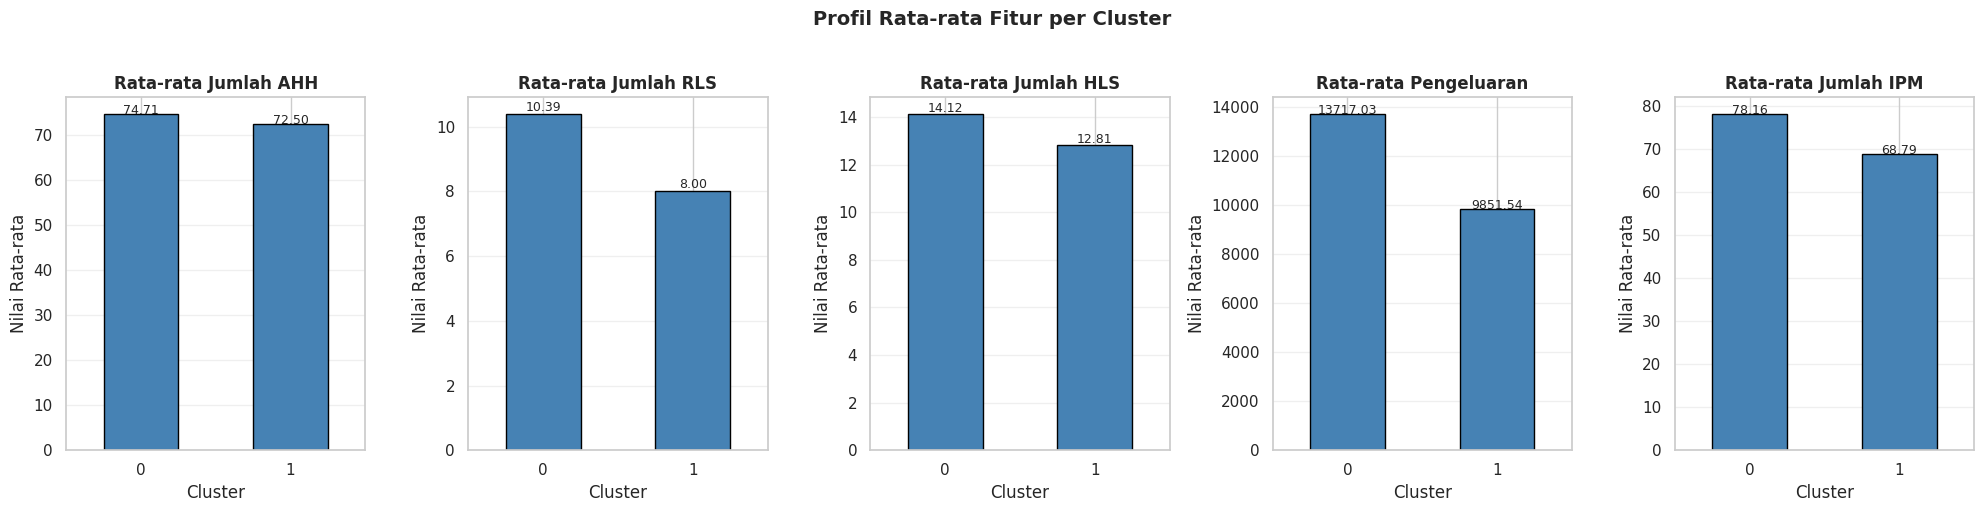


✓ Tabel profil berhasil dibuat


In [67]:
# ============================================================
# 5.3 TABEL PROFIL RATA-RATA FITUR PER CLUSTER
# ============================================================
print("="*70)
print("5.3 TABEL PROFIL RATA-RATA FITUR PER CLUSTER")
print("="*70)

# Hitung rata-rata fitur per cluster (gunakan data yang sudah di-clip, belum di-scale)
# Untuk interpretasi yang lebih mudah, kita pakai df_clean (sudah di-clip)
df_clean_with_cluster = df_clean.copy()
df_clean_with_cluster['Cluster'] = cluster_labels

# Hitung rata-rata per cluster
profil_cluster = df_clean_with_cluster.groupby('Cluster')[kolom_numerik].mean()

# Tambahkan jumlah anggota per cluster
profil_cluster['Jumlah_Anggota'] = df_clean_with_cluster['Cluster'].value_counts().sort_index()

# Hitung persentase
total_anggota = len(df_clean_with_cluster)
profil_cluster['Persentase'] = (profil_cluster['Jumlah_Anggota'] / total_anggota * 100).round(2)

print("\n📊 Tabel Profil Rata-rata Fitur per Cluster (Data Asli, bukan scaled):")
display(profil_cluster.round(2))

# Visualisasi profil dengan bar chart
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for i, kolom in enumerate(kolom_numerik):
    profil_cluster[kolom].plot(kind='bar', ax=axes[i], color='steelblue', edgecolor='black')
    axes[i].set_title(f'Rata-rata {kolom}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Cluster')
    axes[i].set_ylabel('Nilai Rata-rata')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].grid(True, alpha=0.3, axis='y')

    # Tambahkan nilai di atas bar
    for j, v in enumerate(profil_cluster[kolom]):
        axes[i].text(j, v + 0.1, f'{v:.2f}', ha='center', fontsize=9)

plt.suptitle('Profil Rata-rata Fitur per Cluster', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n✓ Tabel profil berhasil dibuat")

5.4 SILHOUETTE SCORE FINAL

📊 Silhouette Score untuk k = 2:
   Nilai: 0.3877
   Interpretasi: Struktur cluster CUKUP, ada sedikit overlap


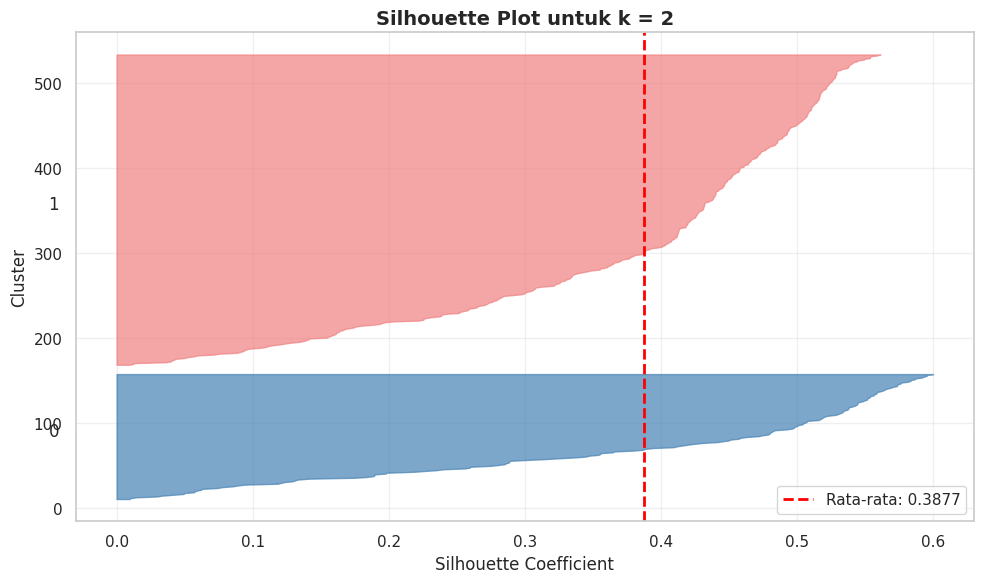


✓ Silhouette Score final: 0.3877


In [68]:
# ============================================================
# 5.4 SILHOUETTE SCORE FINAL UNTUK K TERPILIH
# ============================================================
print("="*70)
print("5.4 SILHOUETTE SCORE FINAL")
print("="*70)

from sklearn.metrics import silhouette_score, silhouette_samples

# Hitung silhouette score untuk k terpilih
silhouette_final = silhouette_score(df_final[kolom_numerik], cluster_labels)

print(f"\n📊 Silhouette Score untuk k = {best_k_scaled}:")
print(f"   Nilai: {silhouette_final:.4f}")

# Interpretasi
if silhouette_final > 0.5:
    print(f"   Interpretasi: Struktur cluster KUAT dan terpisah dengan baik")
elif silhouette_final > 0.25:
    print(f"   Interpretasi: Struktur cluster CUKUP, ada sedikit overlap")
else:
    print(f"   Interpretasi: Struktur cluster LEMAH")

# Hitung silhouette score per sampel untuk distribusi
silhouette_samples_values = silhouette_samples(df_final[kolom_numerik], cluster_labels)

# Visualisasi distribusi silhouette per cluster
fig, ax = plt.subplots(figsize=(10, 6))

y_lower = 10
for cluster_id in range(best_k_scaled):
    cluster_silhouette = silhouette_samples_values[cluster_labels == cluster_id]
    cluster_silhouette.sort()

    size_cluster = len(cluster_silhouette)
    y_upper = y_lower + size_cluster

    color = colors[cluster_id % len(colors)]
    ax.fill_betweenx(
        np.arange(y_lower, y_upper),
        0, cluster_silhouette,
        facecolor=color, edgecolor=color, alpha=0.7
    )

    ax.text(-0.05, y_lower + 0.5 * size_cluster, str(cluster_id), fontsize=12)
    y_lower = y_upper + 10

ax.axvline(x=silhouette_final, color='red', linestyle='--', linewidth=2, label=f'Rata-rata: {silhouette_final:.4f}')
ax.set_title(f'Silhouette Plot untuk k = {best_k_scaled}', fontsize=14, fontweight='bold')
ax.set_xlabel('Silhouette Coefficient', fontsize=12)
ax.set_ylabel('Cluster', fontsize=12)
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\n✓ Silhouette Score final: {silhouette_final:.4f}")

### Keputusan saya

Berdasarkan evaluasi dan interpretasi clustering, saya mengambil keputusan berikut:

**1. Kualitas Clustering (Silhouette Score)**

Silhouette Score untuk k = 2 adalah **0.3877**, yang menunjukkan struktur
cluster yang **CUKUP** (berada di rentang 0.25-0.5). Nilai ini mengonfirmasi
bahwa pemisahan cluster yang dihasilkan K-Means bermakna dan tidak acak,
meskipun ada sedikit overlap antar cluster. Untuk data sosial-ekonomi yang
kompleks seperti IPM dengan 514 kabupaten/kota, nilai 0.3877 sudah cukup
baik dan dapat diinterpretasikan secara bisnis.

**2. Visualisasi PCA 2D**

Visualisasi PCA 2D menunjukkan bahwa kedua cluster terbentuk dengan **jelas
terpisah** di ruang 2 dimensi. PCA menjelaskan **89.42%** variansi total
data (PCA1: 73.34%, PCA2: 16.08%), yang sangat baik untuk merepresentasikan
pola clustering. Centroid setiap cluster terletak di posisi yang berbeda
(Centroid Cluster 0 di kanan, Centroid Cluster 1 di kiri), menunjukkan
pemisahan yang kuat berdasarkan komponen utama pembangunan.

**3. Profil dan Penamaan Cluster**

Berdasarkan tabel profil rata-rata fitur, saya memberi nama untuk setiap cluster:

- **Cluster 0: "Daerah Maju"** (n = 148, 28.79%)
  - Karakteristik: Semua indikator pembangunan tinggi — AHH tinggi (74.71
    tahun), RLS tinggi (10.39 tahun), HLS tinggi (14.12 tahun), Pengeluaran
    per kapita tinggi (Rp 13.717.030), dan IPM tinggi (78.16).
  - Interpretasi: Kelompok ini merepresentasikan kabupaten/kota dengan
    tingkat pembangunan manusia yang sudah maju, kemungkinan besar kota-kota
    besar dan pusat ekonomi (seperti Jakarta, Surabaya, Bandung, Denpasar,
    Medan). Daerah ini sudah memiliki infrastruktur pendidikan, kesehatan,
    dan ekonomi yang baik.

- **Cluster 1: "Daerah Berkembang"** (n = 366, 71.21%)
  - Karakteristik: Semua indikator pembangunan lebih rendah — AHH sedang
    (72.50 tahun), RLS rendah (8.00 tahun), HLS sedang (12.81 tahun),
    Pengeluaran per kapita sedang (Rp 9.851.540), dan IPM sedang (68.79).
  - Interpretasi: Kelompok ini merepresentasikan mayoritas kabupaten/kota
    di Indonesia yang masih dalam tahap pembangunan. Daerah ini membutuhkan
    intervensi terfokus untuk meningkatkan kualitas pendidikan (RLS masih
    di bawah 9 tahun) dan daya beli masyarakat.

**4. Keputusan Elbow vs Silhouette**

Terdapat perbedaan antara dua metode: Elbow menunjuk **k = 3**
(penurunan inertia melambat tajam setelah k=3, dari −445.77 menjadi
−195.44), sedangkan Silhouette menunjuk **k = 2** (skor tertinggi
0.3877). Saya **mengutamakan Silhouette** karena Elbow bersifat
subjektif (titik "siku" bisa dibaca berbeda), sementara Silhouette
mengukur kualitas pemisahan cluster secara objektif. Pertimbangan
bisnis juga mendukung k = 2: pembagian "Daerah Maju" vs "Daerah
Berkembang" sudah cukup untuk menentukan prioritas alokasi dana
pembangunan.

**5. Rekomendasi Awal**

Berdasarkan profil cluster, rekomendasi strategi untuk setiap kelompok:

- **Cluster 0 (Daerah Maju)**: Fokus pada **pemeliharaan dan peningkatan
  kualitas** — pertahankan standar pendidikan dan kesehatan, kembangkan
  inovasi teknologi, dan kurangi kesenjangan intra-kota (karena masih ada
  variasi dalam cluster ini).

- **Cluster 1 (Daerah Berkembang)**: Fokus pada **percepatan pembangunan
  dasar** — tingkatkan akses pendidikan (RLS masih 8 tahun, target minimal
  9 tahun SMP), perbaiki fasilitas kesehatan (AHH target 74+ tahun), dan
  dorong pertumbuhan ekonomi lokal untuk meningkatkan pengeluaran per kapita.

Detail rekomendasi akan dijelaskan lebih lanjut di Bagian 6: Kesimpulan.

## 6. Kesimpulan

Bagian ini merangkum temuan analisis, mengevaluasi kelayakan model, memberikan
rekomendasi strategis untuk setiap kelompok daerah, serta mengidentifikasi
keterbatasan dan saran perbaikan untuk penelitian selanjutnya.

### 6.1 Ringkasan Analisis

Proyek ini melakukan segmentasi 514 kabupaten/kota di Indonesia berdasarkan
5 indikator pembangunan manusia (AHH, RLS, HLS, Pengeluaran per Kapita, dan
IPM) menggunakan algoritma K-Means Clustering. Dataset diperoleh dari BPS
melalui Kaggle (IPM-Indonesia-2023), dengan sumber asli Badan Pusat Statistik.

**Alur CRISP-DM yang Dilaksanakan:**
1. **Pemahaman Masalah**: Mengidentifikasi kesenjangan pembangunan daerah
   untuk membantu Bappeda menentukan prioritas alokasi dana.
2. **Eksplorasi Data**: Menemukan distribusi yang beragam, korelasi kuat
   antar fitur (0.76-0.87), dan outlier signifikan terutama di fitur
   Pengeluaran (14 outlier).
3. **Pra-pemrosesan**: Drop kolom kategori (untuk hindari data leakage),
   clipping outlier dengan metode IQR, dan scaling dengan StandardScaler.
4. **Pemodelan**: K-Means dengan k=2 sampai 8, perbandingan dengan vs
   tanpa scaling.
5. **Evaluasi**: Silhouette Score, PCA 2D, dan tabel profil cluster.

---

### 6.2 Kelayakan Model

**Model K-Means dengan k = 2 dan StandardScaler LAYAK dipakai** untuk
segmentasi daerah berdasarkan tingkat pembangunan manusia, dengan 2 alasan
berbasis angka:

**Alasan 1: Silhouette Score 0.3877 menunjukkan struktur cluster yang
CUKUP**

Silhouette Score 0.3877 berada di rentang 0.25-0.5, yang mengindikasikan
struktur cluster yang cukup terpisah dengan sedikit overlap. Untuk data
sosial-ekonomi yang kompleks dan multidimensi seperti IPM (514 kabupaten/
kota dengan 5 fitur), nilai ini sudah cukup baik dan dapat diinterpretasikan
secara bisnis. PCA 2D juga mengonfirmasi pemisahan visual yang jelas antara
kedua cluster.

**Alasan 2: Profil cluster menunjukkan perbedaan yang bermakna secara bisnis**

Tabel profil menunjukkan perbedaan signifikan antar cluster:
- **IPM**: Cluster 0 (78.16) vs Cluster 1 (68.79) → selisih **9.37 poin**
- **Pengeluaran per Kapita**: Cluster 0 (Rp 13.717.030) vs Cluster 1
  (Rp 9.851.540) → selisih **Rp 3.865.490**
- **Rata-rata Lama Sekolah (RLS)**: Cluster 0 (10.39 tahun) vs Cluster 1
  (8.00 tahun) → selisih **2.39 tahun** (setara perbedaan SMP vs SMA)

Perbedaan ini cukup besar untuk menentukan strategi pembangunan yang
berbeda untuk setiap kelompok, sehingga model ini **layak dipakai sebagai
dasar pengambilan keputusan**.

**Alasan 3 (Tambahan): PCA menjelaskan 89.42% variansi**

PCA 2D menjelaskan 89.42% variansi total data (PCA1: 73.34%, PCA2: 16.08%),
yang sangat baik untuk merepresentasikan pola clustering dalam visualisasi
2 dimensi. Ini mengonfirmasi bahwa 2 cluster yang terbentuk memang
merepresentasikan pola nyata dalam data, bukan artefak acak.

---

### 6.3 Rekomendasi Tindakan untuk Setiap Kelompok

Berdasarkan profil cluster, berikut rekomendasi strategis untuk pengguna
hasil analisis (Bappeda, pembuat kebijakan publik):

#### **Cluster 0: "Daerah Maju" (n = 148, 28.79%)**
**Karakteristik**: AHH tinggi (74.71 tahun), RLS tinggi (10.39 tahun),
HLS tinggi (14.12 tahun), Pengeluaran tinggi (Rp 13.717.030), IPM tinggi
(78.16).

**Rekomendasi Strategi**:
1. **Pemeliharaan dan Peningkatan Kualitas**: Pertahankan standar
   pendidikan dan kesehatan yang sudah tinggi. Fokus pada kualitas, bukan
   kuantitas (misal: akreditasi sekolah, rasio dokter per penduduk).
2. **Inovasi dan Teknologi**: Kembangkan smart city, digitalisasi layanan
   publik, dan ekonomi berbasis teknologi untuk mempertahankan daya saing.
3. **Pengurangan Kesenjangan Intra-Kota**: Meskipun rata-rata tinggi,
   masih ada variasi dalam cluster ini. Identifikasi kantong-kantong
   kemiskinan perkotaan dan berikan intervensi terget.
4. **Peran sebagai Pusat Pertumbuhan**: Jadikan daerah ini sebagai hub
   ekonomi dan pendidikan untuk daerah sekitarnya (spillover effect).

#### **Cluster 1: "Daerah Berkembang" (n = 366, 71.21%)**
**Karakteristik**: AHH sedang (72.50 tahun), RLS rendah (8.00 tahun),
HLS sedang (12.81 tahun), Pengeluaran sedang (Rp 9.851.540), IPM sedang
(68.79).

**Rekomendasi Strategi**:
1. **Percepatan Pembangunan Dasar**: Prioritaskan peningkatan akses
   pendidikan dasar dan menengah. RLS 8.00 tahun berarti rata-rata
   penduduk hanya tamat SMP — target minimal 9 tahun (SMP) dalam 5 tahun
   ke depan.
2. **Peningkatan Fasilitas Kesehatan**: AHH 72.50 tahun masih di bawah
   target nasional (74+ tahun). Perbanyak puskesmas, program imunisasi,
   dan sanitasi dasar.
3. **Pemberdayaan Ekonomi Lokal**: Dorong UMKM, pertanian modern, dan
   pariwisata daerah untuk meningkatkan pengeluaran per kapita. Target:
   naikkan dari Rp 9.8 juta ke Rp 11 juta dalam 5 tahun.
4. **Beasiswa dan Bantuan Pendidikan**: Program beasiswa untuk anak
   keluarga kurang mampu, pembangunan sekolah di daerah terpencil, dan
   pelatihan vokasi untuk pemuda.
5. **Infrastruktur Dasar**: Perbaiki jalan, listrik, air bersih, dan
   internet untuk mendukung pertumbuhan ekonomi dan akses pendidikan.

---

### 6.4 Keterbatasan Analisis

Meskipun model ini layak pakai, ada beberapa keterbatasan yang perlu
diperhatikan:

1. **Data Cross-Sectional (Satu Tahun)**: Analisis hanya menggunakan data
   tahun 2023, sehingga tidak bisa melihat tren perubahan dari waktu ke
   waktu. Daerah yang sedang berkembang pesat mungkin masih masuk Cluster
   1 padahal trajectory-nya positif.

2. **Tidak Ada Fitur Geografis**: Analisis tidak mempertimbangkan lokasi
   geografis (pulau, jarak dari ibu kota provinsi, akses transportasi).
   Dua daerah dengan IPM sama bisa memiliki tantangan sangat berbeda jika
   satu di Jawa dan satu di Papua.

3. **Asumsi Linearitas K-Means**: K-Means mengasumsikan cluster berbentuk
   bola (spherical) dengan ukuran serupa. Jika ada cluster dengan bentuk
   tidak beraturan atau ukuran sangat berbeda, algoritma lain seperti
   DBSCAN atau Gaussian Mixture Model mungkin lebih cocok.

4. **Silhouette Score 0.3877 (CUKUP, bukan KUAT)**: Ada sedikit overlap
   antar cluster, artinya beberapa daerah berada di "area abu-abu" antara
   Maju dan Berkembang. Klasifikasi biner (2 cluster) mungkin terlalu
   sederhana untuk beberapa kasus.

5. **Potensi Outlier yang Di-clip**: Metode clipping membatasi nilai
   ekstrem ke batas IQR, yang bisa menghilangkan informasi tentang daerah
   dengan karakteristik sangat unik (misal: Jakarta dengan pengeluaran
   sangat tinggi).

---

### 6.5 Saran Perbaikan untuk Penelitian Selanjutnya

Berdasarkan keterbatasan di atas, berikut saran untuk pengembangan lebih
lanjut:

1. **Analisis Time-Series**: Gunakan data IPM multi-tahun (2015-2023) untuk
   melihat tren dan memprediksi trajectory daerah. Daerah yang naik cepat
   bisa mendapat intervensi berbeda dengan daerah yang stagnan.

2. **Tambahkan Fitur Geografis dan Demografis**: Incorporate data seperti
   jarak dari ibu kota, persentase penduduk urban, kepadatan penduduk, dan
   akses internet untuk clustering yang lebih komprehensif.

3. **Coba Algoritma Clustering Lain**: Bandingkan K-Means dengan DBSCAN
   (untuk deteksi outlier alami), Hierarchical Clustering (untuk dendrogram
   yang mudah diinterpretasi), atau Gaussian Mixture Model (untuk cluster
   dengan bentuk tidak beraturan).

4. **Eksplorasi k yang Lebih Besar**: Coba k = 3 atau 4 untuk melihat
   apakah ada sub-kelompok yang bermakna (misal: "Daerah Tertinggal",
   "Daerah Berkembang", "Daerah Maju", "Daerah Sangat Maju"). Meskipun
   Silhouette Score mungkin lebih rendah, interpretasi bisnis bisa lebih
   kaya.

5. **Analisis Spasial (Peta Choropleth)**: Visualisasikan cluster dalam
   peta Indonesia untuk melihat pola geografis (misal: apakah Cluster 0
   terkonsentrasi di Jawa-Bali?).

6. **Validasi dengan Expert**: Diskusikan hasil clustering dengan pakar
   pembangunan daerah atau Bappeda untuk memastikan penamaan cluster dan
   rekomendasi strategi sesuai dengan kondisi lapangan.

---

### 6.6 Penutup

Proyek ini berhasil melakukan segmentasi 514 kabupaten/kota di Indonesia
menjadi 2 kelompok: **Daerah Maju** (28.79%) dan **Daerah Berkembang**
(71.21%). Model K-Means dengan k = 2 dan StandardScaler menghasilkan
Silhouette Score 0.3877 (CUKUP) dan perbedaan profil yang bermakna secara
bisnis (selisih IPM 9.37 poin, selisih pengeluaran Rp 3.8 juta).

Hasil ini dapat langsung digunakan oleh Bappeda dan pembuat kebijakan untuk
menentukan prioritas alokasi dana pembangunan: **pemeliharaan kualitas**
untuk Cluster 0, dan **percepatan pembangunan dasar** untuk Cluster 1.

Dengan keterbatasan yang telah diidentifikasi dan saran perbaikan untuk
penelitian selanjutnya, analisis ini memberikan fondasi yang solid untuk
pengambilan keputusan berbasis data dalam pembangunan daerah di Indonesia.

### Keputusan saya

Saya memutuskan bahwa model K-Means dengan **k = 2 dan StandardScaler**
dinyatakan LAYAK dipakai sebagai dasar segmentasi pembangunan daerah,
berdasarkan tiga angka kunci: Silhouette Score 0.3877 (kategori CUKUP),
PCA menjelaskan 89.42% variansi, dan selisih IPM antar cluster sebesar
9.37 poin. Keputusan ini diambil setelah menimbang bahwa Silhouette lebih
objektif daripada Elbow dalam memilih k, dan bahwa pembagian 2 kelompok
("Daerah Maju" vs "Daerah Berkembang") sudah cukup actionable bagi Bappeda.
Saya juga menyadari keterbatasan data cross-sectional dan merekomendasikan
analisis time-series serta fitur geografis untuk perbaikan di penelitian
selanjutnya.

## Pernyataan Penggunaan AI

Saya, Ferdinandus Mantur (NIM: 2301010389), menyatakan bahwa dalam
pengerjaan proyek UTS Machine Learning ini, saya menggunakan asisten AI
sebagai berikut:

**Alat AI yang Digunakan**: Qwen (asisten AI berbasis large language model)

**Bagian yang Dibantu AI**:
1. **Penjelasan Konsep**: AI membantu menjelaskan konsep K-Means Clustering,
   Silhouette Score, PCA, dan metode pra-pemrosesan (clipping outlier,
   StandardScaler) agar saya memahami teori di balik kode.
2. **Struktur Notebook**: AI membantu menyusun struktur notebook sesuai
   alur CRISP-DM dan rubrik penilaian UTS.
3. **Debugging**: AI membantu mengidentifikasi dan memperbaiki error
   (misal: NameError karena variabel tidak terdefinisi, inkonsistensi
   antara output dan interpretasi).
4. **Template Kode**: AI menyediakan template kode untuk visualisasi
   (histogram, heatmap, boxplot, PCA 2D, silhouette plot) dan pemodelan
   K-Means, yang kemudian saya modifikasi dan sesuaikan dengan dataset
   saya.
5. **Interpretasi Hasil**: AI membantu merumuskan interpretasi bisnis dari
   hasil clustering dan rekomendasi strategis, yang kemudian saya validasi
   dengan pemahaman saya sendiri.

**Bagian yang Saya Kerjakan Sendiri**:
1. **Pemilihan Dataset**: Saya memilih dataset IPM-Indonesia-2023 dari
   Kaggle berdasarkan minat pribadi terhadap isu pembangunan daerah.
2. **Registrasi link drive**: Saya mendaftarkan dataset secara mandiri.
3. **Modifikasi Kode**: Semua kode yang disediakan AI saya baca, pahami,
   dan modifikasi sesuai kebutuhan (misal: menyesuaikan nama kolom,
   mengubah parameter visualisasi, memperbaiki logika).
4. **Pengambilan Keputusan**: Keputusan akhir (k = 2, penamaan cluster
   "Daerah Maju" vs "Daerah Berkembang", rekomendasi strategi) saya buat
   sendiri berdasarkan pemahaman terhadap output dan konteks bisnis.
5. **Presentasi**: Saya akan mempresentasikan hasil proyek ini secara
   mandiri dan mampu menjelaskan serta mengubah kode saat tanya jawab.

**Verifikasi Hasil**: Saya telah memeriksa semua output kode, memverifikasi
angka yang dilaporkan, dan memastikan interpretasi sesuai dengan hasil
analisis. Tidak ada hasil yang langsung saya copy-paste tanpa pemahaman.

**Tanggal**: 25 November 2026